<a href="https://colab.research.google.com/github/Piyush-Raj-05/Spam-Mail-Detector/blob/main/spam_mail_detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd


In [4]:
df = pd.read_csv('spam.csv', encoding='latin-1')

In [5]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
897,ham,I'm used to it. I just hope my agents don't dr...,NaN,NaN,NaN
511,ham,Prabha..i'm soryda..realy..frm heart i'm sory,NaN,NaN,NaN
4932,ham,Once free call me sir.,NaN,NaN,NaN
848,ham,Yeah there's barely enough room for the two of...,NaN,NaN,NaN
973,ham,what is your account number?,NaN,NaN,NaN


In [6]:
df.shape

(5572, 5)

In [7]:
#DATA CLEANING

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [11]:
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [12]:
df.sample(5)

,v1,v2
2278,ham,Hmm...Bad news...Hype park plaza $700 studio t...
2902,ham,Tell me pa. How is pain de.
2258,ham,Sad story of a Man - Last week was my b'day. M...
5162,ham,Just send a text. We'll skype later.
2648,ham,"Hi, can i please get a &lt;#&gt; dollar loan..."


In [13]:
df.rename(columns={'v1':'target','v2':'text'},inplace=True)
df.sample(5)

,target,text
4756,ham,"hey, looks like I was wrong and one of the kap..."
1697,ham,Hai priya are you right. What doctor said pa. ...
1205,ham,The whole car appreciated the last two! Dad an...
9,spam,Had your mobile 11 months or more? U R entitle...
3139,spam,sexy sexy cum and text me im wet and warm and ...


In [14]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [17]:
df['target'] = encoder.fit_transform(df['target'])

In [18]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [19]:
df.isnull().sum()

,0
target,0
text,0


In [20]:
df.duplicated().sum()

np.int64(403)

In [21]:
df = df.drop_duplicates(keep='first')

In [22]:
df.duplicated().sum()

np.int64(0)

In [24]:
df.shape

(5169, 2)

In [25]:
#EDA

In [26]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [27]:
df['target'].value_counts()

,count
target,
0,4516
1,653


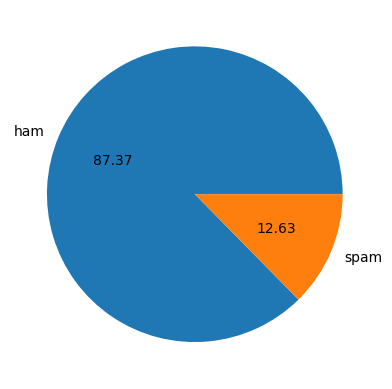

In [30]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(),labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [31]:
#Data is imbalanced

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [54]:
X = df['text']
y = df['target']

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [56]:
#FEATURE EXTRACTION

In [57]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english'
)

In [58]:
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [59]:
#TRAIN NAIVE BAYES CLASSIFIER

In [60]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [61]:
#PREDICTION

In [63]:
y_pred = model.predict(X_test_tfidf)

In [64]:
y_pred

array([0, 0, 0, ..., 1, 0, 0])

In [65]:
#ACCURACY

In [66]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 0.9661508704061895


In [67]:
#CLASSIFICATION REPORT

In [69]:
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



In [70]:
#CONFUSION MATRIX

In [71]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[902   1]
 [ 34  97]]


In [72]:
#TEST A NEW MESSAGE

In [73]:
message = [
    "Congratulations! You have won a free prize. Click now!"
]

message_tfidf = vectorizer.transform(message)
prediction = model.predict(message_tfidf)

if prediction[0] == 0:
    print("The message is classified as 'ham'.")
else:
    print("The message is classified as 'spam'.")

The message is classified as 'spam'.
